# Лабораторная работа 3. Многомерная линейная регрессия

Загрузите датасет players.csv из папки datasets

Предсказываем overall

In [1]:
import pandas as pd
from scipy.stats import iqr
import warnings

warnings.filterwarnings('ignore', category=RuntimeWarning)

df = pd.read_csv('players.csv')

In [2]:
print("df len:", len(df))
print("rows contain NaN:", df.isna().any(axis=1).sum())

df len: 19239
rows contain NaN: 74


In [3]:
df = df.dropna()

# Задание 1
Проведите корреляционный анализ данных. Посчитайте коэффициенты парной корреляции между всеми признаками, нарисуйте heatmap.
Для признаков с максимальной по модулю корреляцией проведите анализ на наличие третьего фактора используя коэффициент частной корреляции.

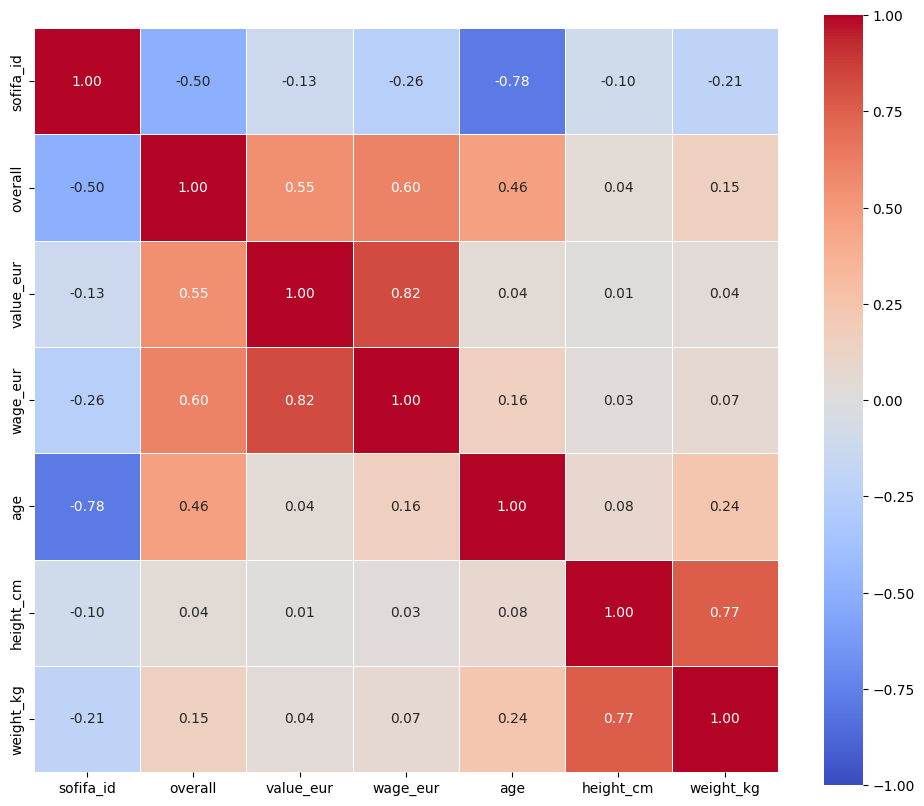

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

#Pearson correlation coefficient
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr, 
    annot=True,         
    fmt=".2f",          
    cmap="coolwarm",    
    vmin=-1, vmax=1,     
    linewidths=0.5,      
    square=True        
)

plt.show()

In [5]:
feature_1, feature_2 = corr.abs().mask(corr == 1.0).unstack().idxmax()
actual_corr = corr.loc[feature_1, feature_2]
print(f"Max corr abs: {actual_corr:.2f} (between '{feature_1}' and '{feature_2}')")

Max corr abs: 0.82 (between 'value_eur' and 'wage_eur')


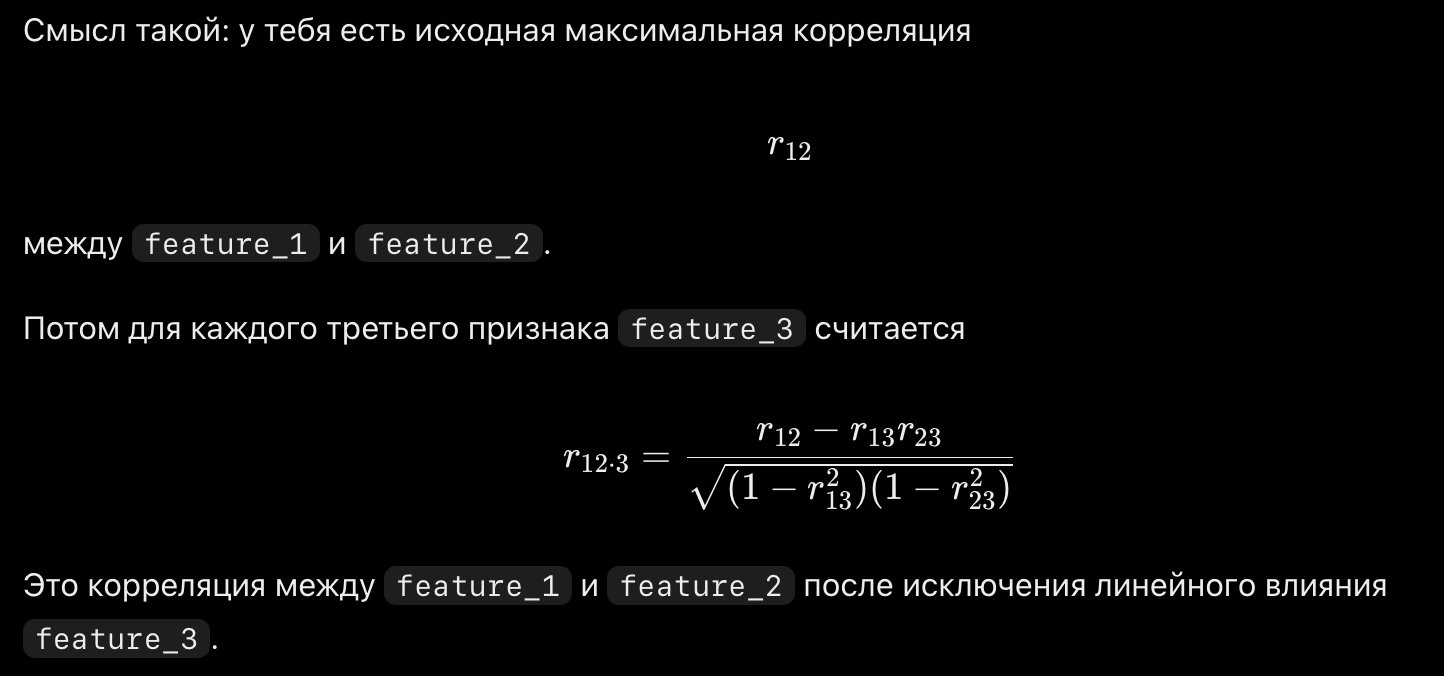

In [6]:
import numpy as np

def partial_corr(corr, x, y, z):
    r_xy = corr.loc[x, y]
    r_xz = corr.loc[x, z]
    r_yz = corr.loc[y, z]

    return (r_xy - r_xz * r_yz) / np.sqrt(
        (1 - r_xz**2) * (1 - r_yz**2)
    )

for feature_3 in corr.columns:
    if feature_3 not in [feature_1, feature_2]:
        r_partial = partial_corr(corr, feature_1, feature_2, feature_3)
        print(f"{feature_3}: {r_partial:.2f}")

# the most influential third factor --- overall

sofifa_id: 0.82
overall: 0.74
age: 0.83
height_cm: 0.82
weight_kg: 0.82


# Задание 2
Разделите выборку на обучающую и тестовую, размер подберите сами. Произведите преобразование стандартизации.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['overall', 'sofifa_id'])  # sofifa_id is irrelevant
y = df['overall']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=666
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Задание 3
Обучите следующие модели многомерной линейной регрессии:
1. Обычная многомерная линейная регрессия
2. Гребневая регрессия
3. Лассо регресиия

Для каждой модели выведите коэффициенты линейной регрессии. Какие из них статистически значимы? Посчитайте метрики MSE, MAE, R^2. Определите самые важные признаки.

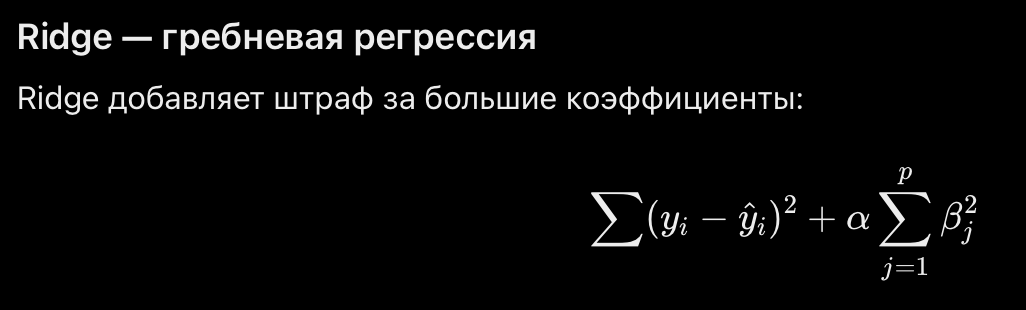 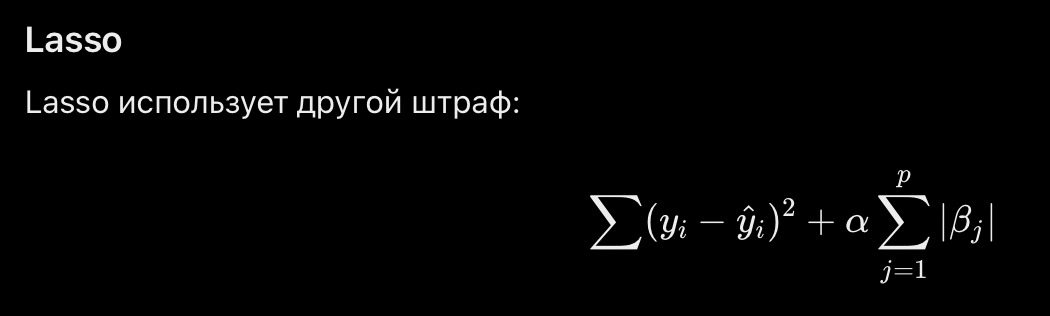 

In [8]:
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

linear = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=1.0)

linear.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

coef_df = pd.DataFrame({
    'feature': X.columns,
    'Linear': linear.coef_,
    'Ridge': ridge.coef_,
    'Lasso': lasso.coef_
})

print(coef_df)

def evaluate(model, name):
    y_pred = model.predict(X_test)

    print(name)
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("R2:", r2_score(y_test, y_pred))
    print()

evaluate(linear, "Linear Regression")
evaluate(ridge, "Ridge")
evaluate(lasso, "Lasso")

     feature    Linear     Ridge     Lasso
0  value_eur  1.949706  1.949615  1.145962
1   wage_eur  2.093194  2.093159  1.916403
2        age  2.678453  2.678291  1.821774
3  height_cm -0.368236 -0.368167  0.000000
4  weight_kg  0.462654  0.462616  0.000000
Linear Regression
MSE: 22.70107715455582
MAE: 3.7230193102501166
R2: 0.5238782913066427

Ridge
MSE: 22.701154068905012
MAE: 3.7230405071210404
R2: 0.52387667814128

Lasso
MSE: 25.13798450574896
MAE: 3.9971028443647025
R2: 0.47276774337633753



In [9]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

ols = sm.OLS(y_train, X_train_sm).fit()

print(ols.summary())
# P>|t| < 0.05 ===> statistically significant

                            OLS Regression Results                            
Dep. Variable:                overall   R-squared:                       0.529
Model:                            OLS   Adj. R-squared:                  0.529
Method:                 Least Squares   F-statistic:                     3442.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:49:29   Log-Likelihood:                -45547.
No. Observations:               15332   AIC:                         9.111e+04
Df Residuals:                   15326   BIC:                         9.115e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         65.7861      0.038   1725.501      0.0

# Задание 4
Для лучшей модели проведите анализ остатков. Для это необходимо нарисовать график предсказанные значения/остатки. Провести статистические тесты на нормальный закон и гетероскедастичность.

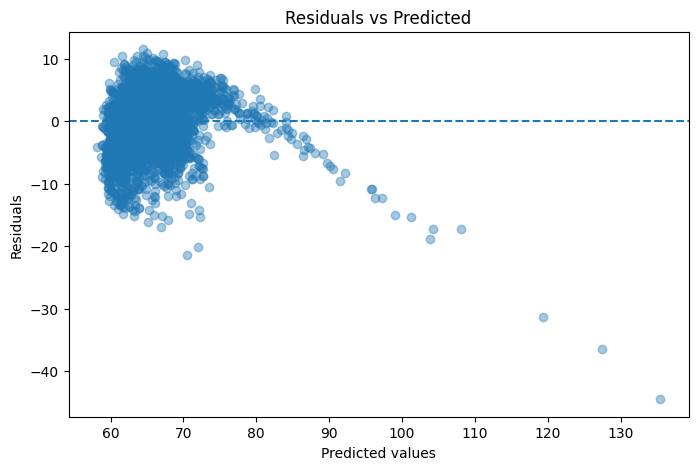

In [10]:
y_pred = linear.predict(X_test)
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, linestyle='--')

plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')

plt.show()

Shapiro p-value: 1.5152137385808615e-29
D'Agostino p-value: 3.608678244488845e-151


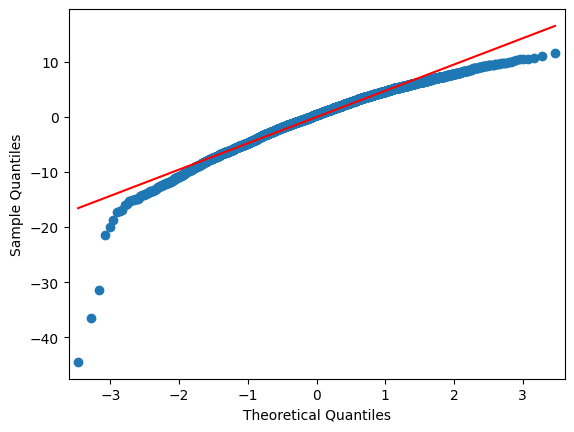

In [11]:
import scipy.stats as stats
import statsmodels.api as sm

data = residuals.dropna()

print("Shapiro p-value:", stats.shapiro(data)[1])
print("D'Agostino p-value:", stats.normaltest(data)[1])

sm.qqplot(data, line="s")
plt.show()

In [12]:
from statsmodels.stats.diagnostic import het_breuschpagan

X_test_sm = sm.add_constant(X_test)

bp = het_breuschpagan(residuals, X_test_sm)

print("LM statistic:", bp[0])
print("LM p-value:", bp[1])
print("F statistic:", bp[2])
print("F p-value:", bp[3])

#bp[1] < 0.05 ===> heteroskedasticity

LM statistic: 772.8325368273987
LM p-value: 8.713217904641843e-165
F statistic: 193.29857950794351
F p-value: 4.261819830098475e-184


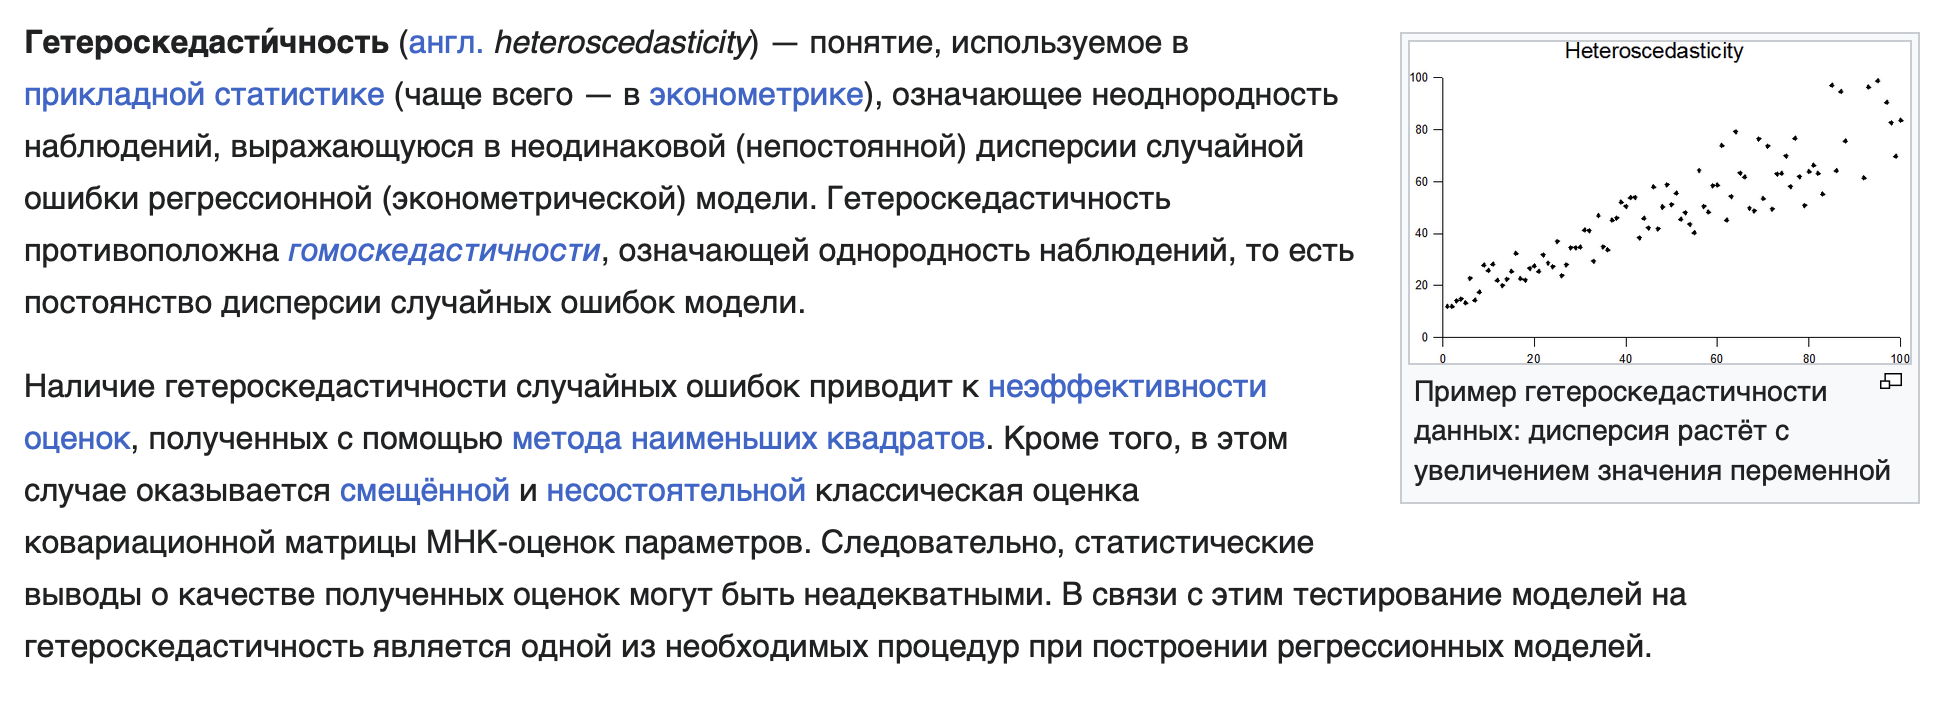